# Sketchy (one sketch per photo) → CSV
Mounts Google Drive, pairs each photo with its sketch, and writes a CSV with columns: `category`, `image_path`, `sketch_path`.

Expected layout:
```
sketchy_dataset_one_sketch/
├── photo/tx_000000000000/<category>/n02691156_58.jpg
└── sketch/tx_000000000000/<category>/n02691156_58-1.png
```

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, re
import pandas as pd

# ---- CONFIG: edit if your folder lives somewhere else ----
ROOT = '/content/drive/MyDrive/sketchy_dataset_one_sketch'
PHOTO_DIR = os.path.join(ROOT, 'photo', 'tx_000000000000')
SKETCH_DIR = os.path.join(ROOT, 'sketch', 'tx_000000000000')
OUT_CSV = os.path.join(ROOT, 'sketchy_pairs.csv')

IMG_EXTS = ('.jpg', '.jpeg', '.png')

for p in (PHOTO_DIR, SKETCH_DIR):
    assert os.path.isdir(p), f'Not found: {p}'
print('Photo categories :', len(os.listdir(PHOTO_DIR)))
print('Sketch categories:', len(os.listdir(SKETCH_DIR)))

Photo categories : 126
Sketch categories: 125


In [3]:
def stem_of_sketch(fname):
    """n02691156_58-1.png -> n02691156_58  (strips the '-<k>' sketch index)"""
    stem = os.path.splitext(fname)[0]
    return re.sub(r'-\d+$', '', stem)

rows, missing_sketch, missing_cat = [], [], []

categories = sorted(d for d in os.listdir(PHOTO_DIR)
                    if os.path.isdir(os.path.join(PHOTO_DIR, d)))

for cat in categories:
    photo_cat_dir = os.path.join(PHOTO_DIR, cat)
    sketch_cat_dir = os.path.join(SKETCH_DIR, cat)

    if not os.path.isdir(sketch_cat_dir):
        missing_cat.append(cat)
        continue

    # map photo-stem -> sketch file for this category
    sketch_map = {}
    for f in sorted(os.listdir(sketch_cat_dir)):
        if f.lower().endswith(IMG_EXTS):
            sketch_map.setdefault(stem_of_sketch(f), f)  # keep first if duplicates

    for f in sorted(os.listdir(photo_cat_dir)):
        if not f.lower().endswith(IMG_EXTS):
            continue
        stem = os.path.splitext(f)[0]
        if stem in sketch_map:
            rows.append({
                'category': cat,
                'image_path': os.path.join(photo_cat_dir, f),
                'sketch_path': os.path.join(sketch_cat_dir, sketch_map[stem]),
            })
        else:
            missing_sketch.append((cat, f))

df = pd.DataFrame(rows, columns=['category', 'image_path', 'sketch_path'])
print(f'Pairs found           : {len(df)}')
print(f'Photos w/o sketch     : {len(missing_sketch)}')
print(f'Categories w/o sketch : {missing_cat}')
df.head()

Pairs found           : 12500
Photos w/o sketch     : 0
Categories w/o sketch : []


,category,image_path,sketch_path
0,airplane,/content/drive/MyDrive/sketchy_dataset_one_ske...,/content/drive/MyDrive/sketchy_dataset_one_ske...
1,airplane,/content/drive/MyDrive/sketchy_dataset_one_ske...,/content/drive/MyDrive/sketchy_dataset_one_ske...
2,airplane,/content/drive/MyDrive/sketchy_dataset_one_ske...,/content/drive/MyDrive/sketchy_dataset_one_ske...
3,airplane,/content/drive/MyDrive/sketchy_dataset_one_ske...,/content/drive/MyDrive/sketchy_dataset_one_ske...
4,airplane,/content/drive/MyDrive/sketchy_dataset_one_ske...,/content/drive/MyDrive/sketchy_dataset_one_ske...


In [4]:
df.to_csv(OUT_CSV, index=False)
print('Saved ->', OUT_CSV)

# per-category counts as a quick sanity check
df['category'].value_counts().sort_index()

Saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/sketchy_pairs.csv


,count
category,
airplane,100
alarm_clock,100
ant,100
ape,100
apple,100
...,...
wheelchair,100
windmill,100
window,100


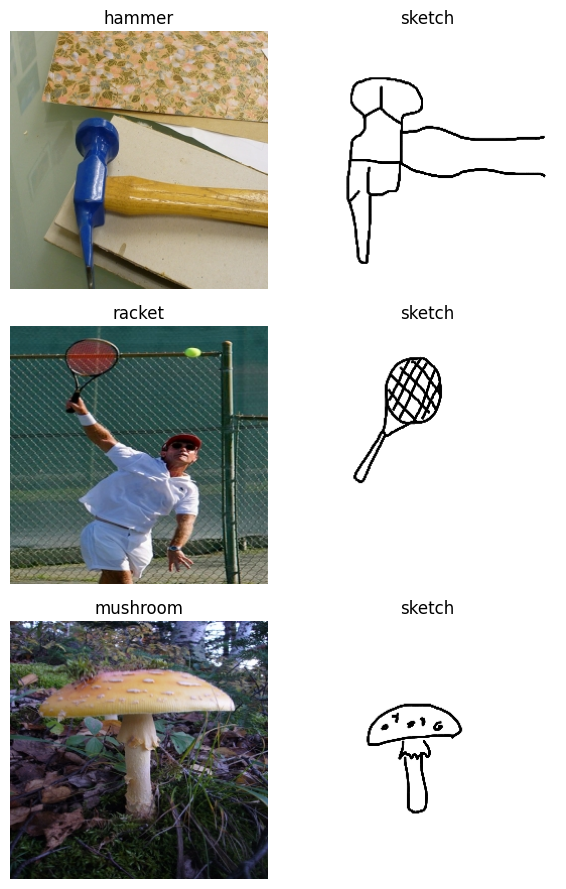

In [5]:
# Optional: visually verify a few random pairs
import matplotlib.pyplot as plt
from PIL import Image

sample = df.sample(3, random_state=0)
fig, axes = plt.subplots(3, 2, figsize=(6, 9))
for i, (_, r) in enumerate(sample.iterrows()):
    axes[i, 0].imshow(Image.open(r.image_path));  axes[i, 0].set_title(r.category)
    axes[i, 1].imshow(Image.open(r.sketch_path)); axes[i, 1].set_title('sketch')
    axes[i, 0].axis('off'); axes[i, 1].axis('off')
plt.tight_layout(); plt.show()

In [2]:
!pip install -q -U "transformers>=4.57" accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 50.4 MB/s eta 0:00:00


In [8]:
import os, torch, pandas as pd
from PIL import Image

# ---------------- CONFIG ----------------
ROOT = '/content/drive/MyDrive/sketchy_dataset_one_sketch'
CSV_IN = os.path.join(ROOT, 'sketchy_pairs.csv')
CSV_OUT = os.path.join(ROOT, 'sketchy_captions_sample.csv')

N = 200
RANDOM_SAMPLE = True   # False = literally the first N rows (will cover only the first few categories alphabetically)
BATCH_SIZE = 4
MAX_NEW_TOKENS = 60    # hard cap on caption length

MODEL_ID = 'Qwen/Qwen3-VL-2B-Instruct'
MAX_SIDE = 448          # photos are downscaled to this longest side before captioning

# Prompt template: {category} is filled with the folder name (underscores -> spaces)
PROMPT = (
    "The main subject is a {category}. "
    "Write ONE concise caption (max 15 words) describing the object, "
    "its identity, distinctive features, parts, and meaningful semantic attributes. "
    "Emphasize the most important and distinguishing details. "
    "Mention colour, pose, action, or background only when relevant. "
    "Do not invent details. "
    "Do not start with 'A photo of' or 'An image of'. "
    "Output only the caption."
)
# ----------------------------------------

df = pd.read_csv(CSV_IN)
df = df.sample(N, random_state=0) if RANDOM_SAMPLE else df.head(N)
df = df.reset_index(drop=True)
print(len(df), 'rows,', df['category'].nunique(), 'categories')

200 rows, 99 categories


In [5]:
import os

mydrive_path = '/content/drive/MyDrive'
if os.path.exists(mydrive_path):
    print("Successfully mounted Drive. Listing top-level folders in MyDrive to find your dataset:")
    folders = [f for f in os.listdir(mydrive_path) if os.path.isdir(os.path.join(mydrive_path, f))]
    for folder in sorted(folders):
        if 'sketchy' in folder.lower():
            print(f" -> FOUND MATCH: {folder}")
        else:
            print(f"    {folder}")
else:
    print("Error: /content/drive/MyDrive does not exist. Please run the first cell to mount your Google Drive.")

Error: /content/drive/MyDrive does not exist. Please run the first cell to mount your Google Drive.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

# T4 has no native bf16 -> use fp16 there, bf16 on Ampere+ GPUs
use_bf16 = torch.cuda.get_device_capability()[0] >= 8
dtype = torch.bfloat16 if use_bf16 else torch.float16

model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID, torch_dtype=dtype, device_map='auto'
)
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = 'left'   # needed for batched generation

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

In [15]:
def load_img(p):
    im = Image.open(p).convert('RGB')
    im.thumbnail((MAX_SIDE, MAX_SIDE))
    return im

def make_prompt(cat):
    return PROMPT.format(category=cat.replace('_', ' '))

@torch.no_grad()
def caption_batch(paths, cats):
    messages = [
        [{'role': 'user', 'content': [
            {'type': 'image', 'image': load_img(p)},
            {'type': 'text', 'text': make_prompt(c)},
        ]}]
        for p, c in zip(paths, cats)
    ]
    inputs = processor.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors='pt', padding=True,
    ).to(model.device)

    # Using a tighter max_new_tokens limit (e.g. 20 tokens (~15 words)) to force early stopping at model level
    out = model.generate(**inputs, max_new_tokens=20, do_sample=False)
    out = [o[len(i):] for i, o in zip(inputs['input_ids'], out)]
    return [t.strip() for t in processor.batch_decode(out, skip_special_tokens=True)]

# Quick test to see how the model behaves with the tighter limit
test = df.head(4)
for c, cap in zip(test.category, caption_batch(test.image_path.tolist(), test.category.tolist())):
    print(f'[{c}] {cap}')

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[hammer] Blue-handled hammer with wooden handle, resting on cardboard.
[racket] A red tennis racket in mid-swing, poised to strike a yellow ball.
[mushroom] A vibrant yellow mushroom with white spots, growing on moss in a forest.
[axe] A black-handled axe rests on a log, ready for use.


In [16]:
from tqdm.auto import tqdm

captions = []
for i in tqdm(range(0, len(df), BATCH_SIZE)):
    chunk = df.iloc[i:i + BATCH_SIZE]
    captions += caption_batch(chunk.image_path.tolist(), chunk.category.tolist())

df['caption'] = captions
df.to_csv(CSV_OUT, index=False)
print('Saved ->', CSV_OUT)

  0%|          | 0/50 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

Saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/sketchy_captions_sample.csv


0,,"hammerBlue-handled hammer with wooden handle, resting on cardboard."
1,,"racketA red tennis racket in mid-swing, poised to strike a yellow ball."
2,,"mushroomA vibrant yellow mushroom with white spots, growing on moss in a forest."
3,,"axeA black-handled axe rests on a log, ready for use."
4,,"benchA weathered wooden bench with dark green slats, positioned on a leaf-covered path."
5,,racketA red tennis racket held by a player in motion on a clay court.
6,,"trumpetA close-up of a silver French horn held by hands, showcasing its intricate tubing and polished surface."
7,,"lobsterA large, dark-colored lobster with yellow bands on its claws, resting in a boat."
8,,"giraffeA close-up of a giraffe with distinctive horn-like tufts, showcasing its patterned coat and"
9,,"saxophoneGolden saxophone played by man in denim jacket, focused on music."
10,,fishA vibrant clownfish swims near a sea anemone in a coral reef.

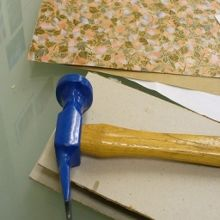
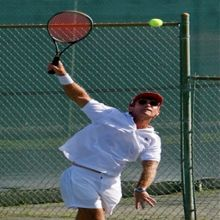
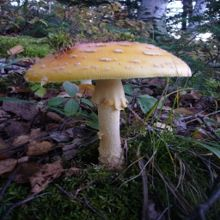
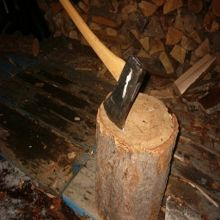
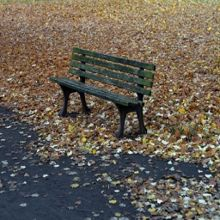
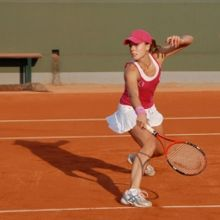
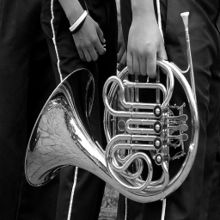
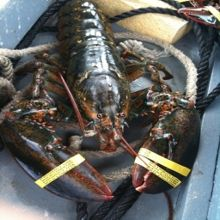
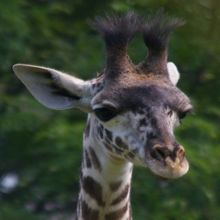
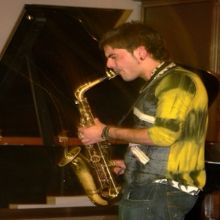
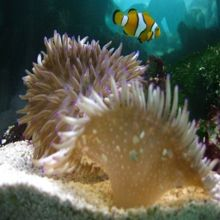
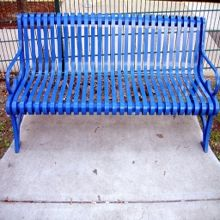
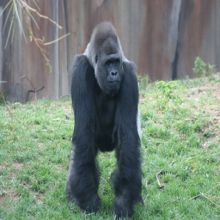
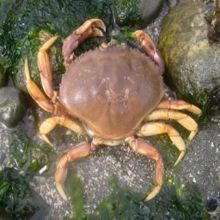
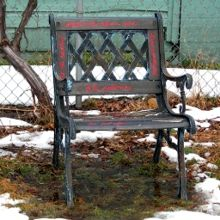
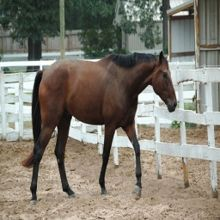
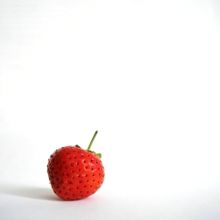
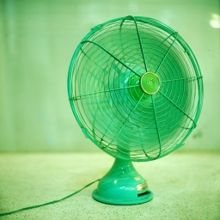
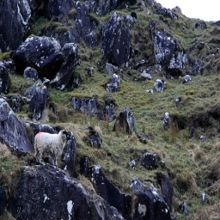
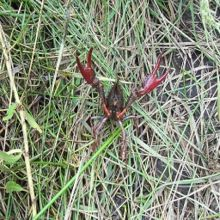

In [17]:
import io, base64
from IPython.display import HTML, display

def thumb_b64(path, size=220):
    im = Image.open(path).convert('RGB'); im.thumbnail((size, size))
    buf = io.BytesIO(); im.save(buf, format='JPEG', quality=80)
    return base64.b64encode(buf.getvalue()).decode()

def show(start=0, n=20):
    rows = ''
    for i, r in df.iloc[start:start + n].iterrows():
        rows += (f"<tr><td style='padding:4px'>{i}</td>"
                 f"<td><img src='data:image/jpeg;base64,{thumb_b64(r.image_path)}'></td>"
                 f"<td style='padding:6px'><b>{r.category}</b><br>{r.caption}</td></tr>")
    display(HTML(f'<table>{rows}</table>'))

show(0, 20)    # change start to page through: show(20, 20), show(40, 20), ...

In [18]:
# Sanity stats: caption length, and does the caption mention the category word?
df['n_words'] = df.caption.str.split().str.len()
df['mentions_cat'] = [c.replace('_', ' ') in cap.lower() for c, cap in zip(df.category, df.caption)]
print(df.n_words.describe())
print('Mention category word:', df.mentions_cat.mean().round(3))

count    200.000000
mean      13.205000
std        2.544671
min        8.000000
25%       11.000000
50%       13.000000
75%       15.000000
max       18.000000
Name: n_words, dtype: float64
Mention category word: 0.895


### Strictly Enforcing the 15-Word Limit
Since Vision-Language Models sometimes ignore length constraints in prompts, we can programmatically truncate any generated caption to exactly 15 words. Let's create a cleaned column `strict_caption` and check the updated stats.

In [ ]:
def enforce_word_limit(caption, max_words=15):
    words = caption.split()
    if len(words) > max_words:
        # Reconstruct caption with only the first N words and add a period if missing
        truncated = " ".join(words[:max_words])
        if not truncated.endswith('.'):
            truncated += '.'
        return truncated
    return caption

# Apply the strict truncation constraint
df['caption'] = df['caption'].apply(lambda x: enforce_word_limit(x, max_words=15))

# Recalculate stats
df['n_words'] = df['caption'].str.split().str.len()
display(df['n_words'].describe())

# Save the strictly bounded captions back to the CSV
df.to_csv(CSV_OUT, index=False)
print("Saved truncated captions back to:", CSV_OUT)